<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/mean_tension_libration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Average pendulum tension in the libration regime ($0^{\circ}<\theta<180^{\circ}$).

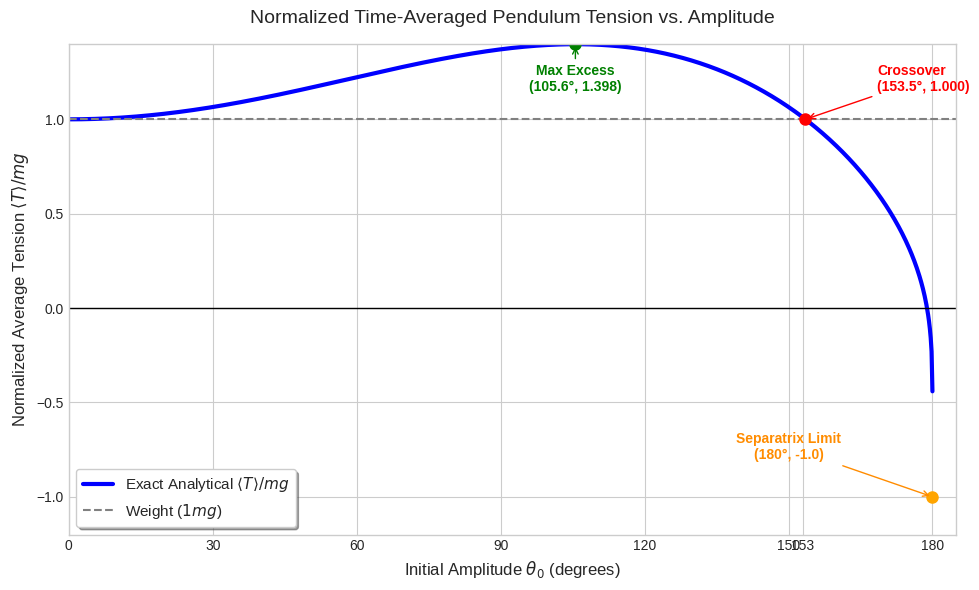

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk, ellipe

# --- 1. Compute the exact theoretical data ---
# Create an array of angles from 0 to just under 180 degrees
# We stop at 179.99 to avoid the singularity at 180 where K(k) diverges to infinity
theta_deg = np.linspace(0, 179.99, 1000)
theta_rad = np.deg2rad(theta_deg)

# Calculate the elliptic modulus squared (k^2).
# Note: scipy's ellipk and ellipe take the parameter m = k^2 as their argument!
k_sq = np.sin(theta_rad / 2)**2

# Compute Complete Elliptic Integrals of the First (K) and Second (E) kind
K_val = ellipk(k_sq)
E_val = ellipe(k_sq)

# Calculate the normalized time-averaged tension <T>/mg using the derived formula:
# <T>/mg = 6 * (E(k)/K(k)) + 4k^2 - 5
T_ratio = 6 * (E_val / K_val) + 4 * k_sq - 5

# --- 2. Find Key Points for Annotations ---
# Find the exact peak (Max Excess)
max_idx = np.argmax(T_ratio)
theta_max = theta_deg[max_idx]
T_max = T_ratio[max_idx]

# Find the Crossover Point where <T> = 1 mg
# We find where the difference from 1.0 crosses zero
crossover_idx = np.argmin(np.abs(T_ratio - 1.0)[max_idx:]) + max_idx
theta_cross = theta_deg[crossover_idx]

# --- 3. Plotting ---
plt.figure(figsize=(10, 6))
plt.style.use('seaborn-v0_8-whitegrid')

# Plot the main curve
plt.plot(theta_deg, T_ratio, '-', color='blue', linewidth=3, label=r'Exact Analytical $\langle T \rangle / mg$')

# Draw reference lines
plt.axhline(y=1, color='gray', linestyle='--', linewidth=1.5, label='Weight ($1 mg$)')
plt.axhline(y=0, color='black', linestyle='-', linewidth=1)

# Annotate Max Excess
plt.plot(theta_max, T_max, 'go', markersize=8)
plt.annotate(f'Max Excess\n({theta_max:.1f}°, {T_max:.3f})',
             xy=(theta_max, T_max), xytext=(theta_max, T_max - 0.25),
             ha='center', color='green', fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='green'))

# Annotate Crossover
plt.plot(theta_cross, 1.0, 'ro', markersize=8)
plt.annotate(f'Crossover\n({theta_cross:.1f}°, 1.000)',
             xy=(theta_cross, 1.0), xytext=(theta_cross + 15, 1.15),
             ha='left', color='red', fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='red'))

# Annotate Separatrix Limit (Approaching 180)
plt.plot(180, -1, 'o', color='orange', markersize=8)
plt.annotate('Separatrix Limit\n(180°, -1.0)',
             xy=(180, -1), xytext=(150, -0.8),
             ha='center', color='darkorange', fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='darkorange'))

# Formatting the plot
plt.title('Normalized Time-Averaged Pendulum Tension vs. Amplitude', fontsize=14, pad=15)
plt.xlabel(r'Initial Amplitude $\theta_0$ (degrees)', fontsize=12)
plt.ylabel(r'Normalized Average Tension $\langle T \rangle / mg$', fontsize=12)

# Set custom x-ticks to match important milestones
custom_ticks = [0, 30, 60, int(theta_cross), 90, 120, 150, 180]
plt.xticks(custom_ticks)
plt.xlim(0, 185)
plt.ylim(-1.2, 1.4)

plt.legend(loc='lower left', frameon=True, shadow=True, fontsize=11)
plt.tight_layout()

# Display the plot
plt.show()